# Probe playground: look inside one result

`probe_paradigms.ipynb` says **whether** a combination passes a probe at the end of
its budget. This notebook shows **how it got there**: it trains in this process and
reads the networks after every training iteration, so each output (a value or an
action) becomes a curve over environment steps, drawn against the exact answer
and its tolerance band.

That separates the usual explanations of a failure:

| What the curve does | What it means |
|---|---|
| still moving toward the answer at the end | too little budget: train longer |
| settles at a wrong value | something is wrong (or the settings cannot reach it): compare with another paradigm or algorithm |
| reaches the answer, then swings around it | learning too aggressive for this setting (learning rate, batch) |
| differs a lot between seeds | one run is not enough to judge |

**How to use it.** Each experiment is a list of variants: the same probe with
different algorithms, paradigms, seeds, budgets or settings. `trace` trains one
variant; `plot` draws all of them. Nothing is written to disk, and a variant takes
seconds to a few minutes. Section c is a worked example; section d is yours.

**Limits.** In CTCE and CTDE the value is the group's; for DTDE the agents'
values are summed so all paradigms are drawn on the same scale. SAC's value in
probe 3 includes its entropy bonus, so it settles above the plain answer drawn
here (see `probe_paradigms.ipynb`).

In [1]:
import os
import sys
from dataclasses import dataclass, field
from pathlib import Path

# RL root; imports use its parent so market core/ stays separate.
ROOT = next(p / "RL" for p in [Path.cwd(), *Path.cwd().parents] if (p / "RL" / "core").is_dir())
sys.path.insert(0, str(ROOT.parent))
os.environ["PYTHONPATH"] = os.pathsep.join(filter(None, [str(ROOT.parent), os.environ.get("PYTHONPATH", "")]))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ray
from ray.rllib.utils.metrics import (
    ENV_RUNNER_RESULTS,
    LEARNER_RESULTS,
    NUM_ENV_STEPS_SAMPLED_LIFETIME,
)

from RL.core.envs.probes import (
    ActionProbe,
    ConstantProbe,
    DiscountProbe,
    ObsActionProbe,
    ObservationProbe,
)
from RL.core.fixed.config import build_config
from RL.core.fixed.grouping import GROUP
from RL.core.fixed.policy import Policy
from RL.core.fixed.train import learner_modules

pd.set_option("display.precision", 3)
if not ray.is_initialized():
    ray.init(num_cpus=2, include_dashboard=False, log_to_driver=False)

2026-10-13 16:44:53,680	INFO worker.py:2012 -- Started a local Ray instance.


C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\_private\worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(


## a. Settings and the probes

The same probes and fast settings as `probe_paradigms.ipynb`. A variant can
override any of them.

In [2]:
# number: (name, environment, discount, agent names whose sorted order differs)
PROBES = {
    1: ("Constant", ConstantProbe, 0.99, False),
    2: ("Observation", ObservationProbe, 0.99, False),
    3: ("Discount", DiscountProbe, 0.5, False),
    4: ("Action", ActionProbe, 0.99, True),
    5: ("Obs -> action", ObsActionProbe, 0.99, True),
}
MODEL = {"fcnet_hiddens": [64, 64]}
TRAINING = {
    "ppo": {"lr": 1e-3, "train_batch_size_per_learner": 500, "minibatch_size": 64,
            "num_epochs": 10},
    "appo": {"lr": 1e-3, "train_batch_size_per_learner": 200},
    "sac": {"actor_lr": 1e-3, "critic_lr": 1e-3,
            "num_steps_sampled_before_learning_starts": 200, "training_intensity": 32},
}
TOLERANCE = 0.15

## b. The tools

- `trace(...)` trains one variant and records, after every iteration, every
  output the probe checks, the policy's entropy (PPO, APPO) or temperature (SAC),
  and the number of samples the learner has trained on.
- `plot(traces)` draws each checked output against the answer (dashed) and its
  tolerance band (grey), one line per variant, plus the learner's health.
- `final(traces)` lists each variant's last outputs and whether they pass.

In [3]:
@dataclass
class Trace:
    label: str
    frame: pd.DataFrame  # one row per iteration
    expected: dict  # output -> exact answer
    tolerance: dict = field(default_factory=dict)  # output -> allowed error


def trace(algorithm: str, paradigm: str, probe: int, budget: int, *, seed: int = 0,
          training: dict | None = None, model: dict | None = None,
          label: str | None = None) -> Trace:
    """Train one variant in this process; read its networks after every iteration."""
    _, env_class, gamma, scramble = PROBES[probe]
    env_config = {"n_agents": 3, "scramble_ids": scramble}
    settings = TRAINING[algorithm] | {"gamma": gamma} | (training or {})
    config = build_config(algorithm, paradigm, env_class, env_config, seed=seed,
                          training=settings, model=MODEL | (model or {}))
    env = env_class(env_config)
    checks = env.checks(settings["gamma"])
    expected, tolerance = {}, {}
    for check in checks:
        if check.value is not None:
            out = f"{check.name} | value"
            expected[out] = sum(check.value.values())
            tolerance[out] = TOLERANCE * max(1.0, abs(expected[out]))
        if check.action is not None:
            for agent, value in check.action.items():
                out = f"{check.name} | action {agent}"
                expected[out], tolerance[out] = value, TOLERANCE

    algo = config.build_algo()
    rows, trained = [], 0
    try:
        steps = 0
        while steps < budget:
            result = algo.train()
            steps = result[ENV_RUNNER_RESULTS][NUM_ENV_STEPS_SAMPLED_LIFETIME]
            learners = {k: v for k, v in result.get(LEARNER_RESULTS, {}).items()
                        if isinstance(v, dict) and k != "__all_modules__"}
            trained += sum(v.get("num_module_steps_trained", 0) for v in learners.values())
            policy = Policy(learner_modules(algo), paradigm, env)
            row = {"env steps": steps, "samples trained": trained}
            for check in checks:
                if check.value is not None:
                    row[f"{check.name} | value"] = sum(policy.values(check.obs).values())
                if check.action is not None:
                    actions = policy.act(check.obs)
                    for agent in check.action:
                        row[f"{check.name} | action {agent}"] = float(actions[agent][0])
            for metric in ("entropy", "alpha_value"):
                values = [v[metric] for v in learners.values() if metric in v]
                if values:
                    row[metric] = float(np.mean(values))
            rows.append(row)
    finally:
        algo.stop()
    name = label or f"{algorithm.upper()} {paradigm.upper()} seed {seed}"
    return Trace(name, pd.DataFrame(rows), expected, tolerance)


def plot(traces: list[Trace], health: bool = True) -> None:
    """Each checked output over environment steps, one line per variant."""
    outputs = list(traces[0].expected)
    panels = outputs + (["entropy / alpha"] if health else [])
    cols = min(3, len(panels))
    rows = int(np.ceil(len(panels) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.2 * rows), squeeze=False)
    for ax, panel in zip(axes.flat, panels):
        for t in traces:
            frame = t.frame
            if panel == "entropy / alpha":
                column = "alpha_value" if "alpha_value" in frame else "entropy"
                if column in frame:
                    ax.plot(frame["env steps"], frame[column], label=f"{t.label} ({column})")
            elif panel in frame:
                ax.plot(frame["env steps"], frame[panel], label=t.label)
        if panel != "entropy / alpha":
            answer, tol = traces[0].expected[panel], traces[0].tolerance[panel]
            ax.axhline(answer, color="black", ls="--", lw=1)
            ax.axhspan(answer - tol, answer + tol, color="grey", alpha=0.15)
        ax.set_title(panel, fontsize=10)
        ax.set_xlabel("environment steps")
    for ax in list(axes.flat)[len(panels):]:
        ax.axis("off")
    axes.flat[0].legend(fontsize=7)
    plt.tight_layout()
    plt.show()


def final(traces: list[Trace]) -> pd.DataFrame:
    """The last outputs of every variant, and whether each is within tolerance."""
    rows = {}
    for t in traces:
        last = t.frame.iloc[-1]
        row = {"env steps": int(last["env steps"])}
        for out, answer in t.expected.items():
            row[out] = last[out]
        row["pass"] = all(abs(last[o] - a) <= t.tolerance[o] for o, a in t.expected.items())
        rows[t.label] = row
    expected = {"env steps": None, **traces[0].expected, "pass": None}
    return pd.DataFrame({"expected": expected, **rows}).T

## c. Worked example: APPO on probe 1

In `probe_paradigms.ipynb` (fast settings, 3,000 steps) APPO-CTDE failed probe 1
with a group value of 2.47 against 3. Is that the budget or CTDE?

Two facts point at the answer before training anything:

- In probe 1 the action does not matter, so only the critic is tested, and CTCE
  and CTDE have **the same critic** (RLlib's, on the joint observation). They
  differ only in the actor. If CTDE failed for a CTDE reason, CTCE would not show
  the same curve.
- APPO trains each batch of 200 steps at most twice, so it makes far fewer
  updates per step than PPO (30 epochs over each batch). Its value should
  converge in more steps.

So: CTCE and CTDE with the same seed, two seeds each, and DTDE for reference,
three times the budget.

2026-10-13 16:44:59,499	WARNING algorithm_config.py:5053 -- You are running APPO on the new API stack! This is the new default behavior for this algorithm. If you don't want to use the new API stack, set `config.api_stack(enable_rl_module_and_learner=False,enable_env_runner_and_connector_v2=False)`. For a detailed migration guide, see here: https://docs.ray.io/en/master/rllib/new-api-stack-migration-guide.html


C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
The `JsonLogger interface is deprecated in favor of the `ray.tune.json.JsonLoggerCallback` interface and will be removed in Ray 2.7.
  self._loggers.append(cls(self.config, self.logdir, self.trial))
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be 

2026-10-13 16:45:00,185	WARNING deprecation.py:50 -- DeprecationWarning: `ray.rllib.algorithms.appo.torch.appo_torch_rl_module.APPOTorchRLModule` has been deprecated. Use `ray.rllib.algorithms.appo.torch.default_appo_torch_rl_module.DefaultAPPOTorchRLModule` instead. This will raise an error in the future!


2026-10-13 16:45:00,276	WARNING deprecation.py:50 -- DeprecationWarning: `RLModule(config=[RLModuleConfig object])` has been deprecated. Use `RLModule(observation_space=.., action_space=.., inference_only=.., model_config=.., catalog_class=..)` instead. This will raise an error in the future!


2026-10-13 16:45:02,478	WARNING util.py:61 -- Install gputil for GPU system monitoring.


...

2026-10-13 16:47:06,787	WARNING util.py:61 -- Install gputil for GPU system monitoring.


C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
The `JsonLogger interface is deprecated in favor of the `ray.tune.json.JsonLoggerCallback` interface and will be removed in Ray 2.7.
  self._loggers.append(cls(self.config, self.logdir, self.trial))
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be 

2026-10-13 16:47:53,351	WARNING util.py:61 -- Install gputil for GPU system monitoring.


C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
The `JsonLogger interface is deprecated in favor of the `ray.tune.json.JsonLoggerCallback` interface and will be removed in Ray 2.7.
  self._loggers.append(cls(self.config, self.logdir, self.trial))
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be 

2026-10-13 16:49:13,561	WARNING util.py:61 -- Install gputil for GPU system monitoring.


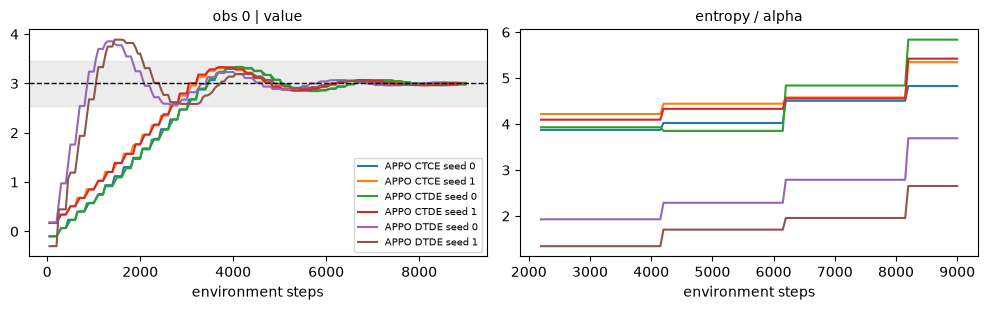

,env steps,obs 0 | value,pass
expected,NaN,3.0,NaN
APPO CTCE seed 0,9000,2.983,True
APPO CTCE seed 1,9000,2.998,True
APPO CTDE seed 0,9000,2.98,True
APPO CTDE seed 1,9000,3.004,True
APPO DTDE seed 0,9000,3.007,True
APPO DTDE seed 1,9000,3.011,True


In [4]:
example = [
    trace("appo", paradigm, probe=1, budget=9_000, seed=seed)
    for paradigm in ("ctce", "ctde", "dtde")
    for seed in (0, 1)
]
plot(example)
final(example)

**Reading it.** With the same seed, CTCE and CTDE draw the same curve: the
critic is the same network with the same start, and the actor plays no part in
probe 1. Both climb slowly, enter the tolerance band only around 3,000 steps
(where the fast preset stopped, so the end value fell either side of the edge),
overshoot a little and settle at 3 by about 6,000 steps. So the failure was the
budget, not CTDE: the fast preset now gives APPO 6,000 steps on probes 1-3.

DTDE gets there much sooner: each agent's critic learns a target of 1 instead of
the group's 3, and the three critics are trained separately. The entropy panel
rises for everyone because in probe 1 the reward does not depend on the action, so
only the entropy bonus acts on the policy's spread.

## d. Your experiment

Edit the variants and run. Examples of questions:

- Is a failure the budget? Same variant, `budget` × 3.
- Is it the seed? Same variant, `seed` 0, 1, 2.
- Is it the paradigm? Same algorithm and seed, the three paradigms.
- Is it a setting? `training={"lr": 3e-4}`, `model={"fcnet_hiddens": [256, 256]}`,
  `training={"train_batch_size_per_learner": 1000}`, ... with `label="..."` to name
  the line.

2026-10-13 16:50:35,417	WARNING algorithm_config.py:5053 -- You are running PPO on the new API stack! This is the new default behavior for this algorithm. If you don't want to use the new API stack, set `config.api_stack(enable_rl_module_and_learner=False,enable_env_runner_and_connector_v2=False)`. For a detailed migration guide, see here: https://docs.ray.io/en/master/rllib/new-api-stack-migration-guide.html


C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
The `JsonLogger interface is deprecated in favor of the `ray.tune.json.JsonLoggerCallback` interface and will be removed in Ray 2.7.
  self._loggers.append(cls(self.config, self.logdir, self.trial))
C:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be 

2026-10-13 16:50:35,973	WARNING util.py:61 -- Install gputil for GPU system monitoring.


2026-10-13 16:53:42,632	WARNING util.py:61 -- Install gputil for GPU system monitoring.


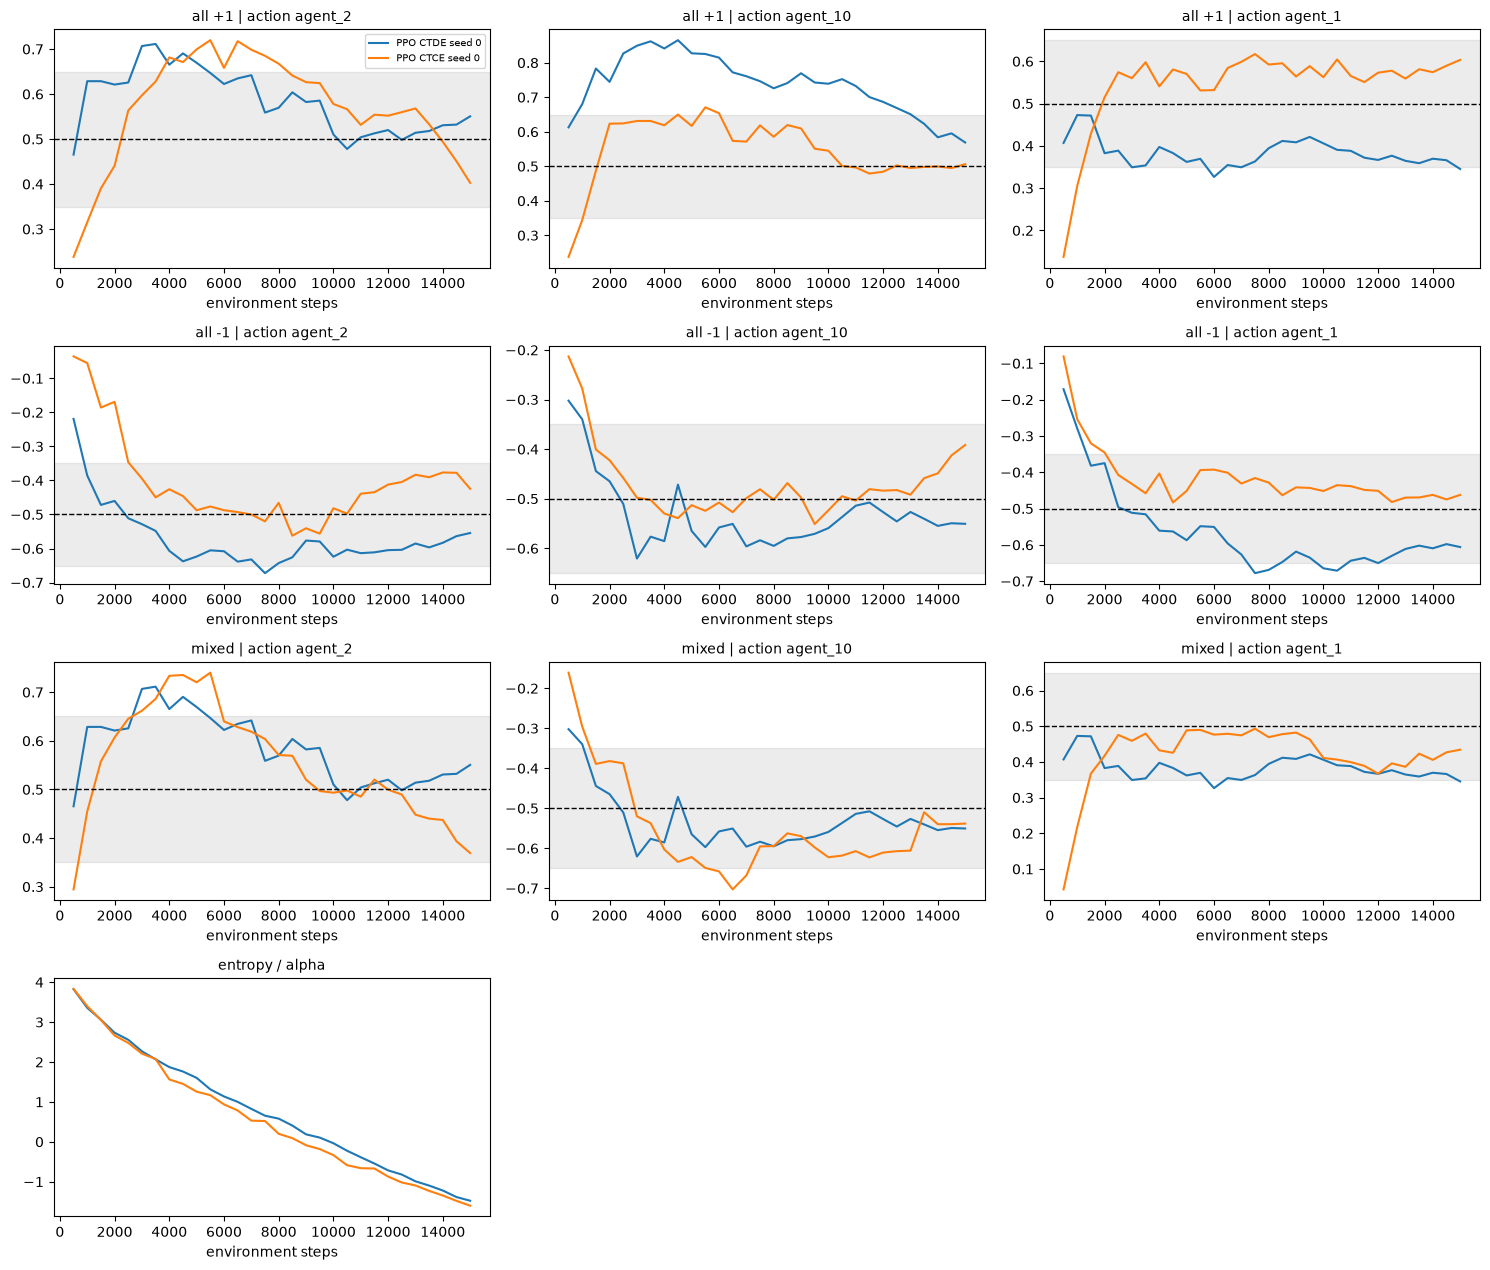

,env steps,all +1 | action agent_2,all +1 | action agent_10,all +1 | action agent_1,all -1 | action agent_2,all -1 | action agent_10,all -1 | action agent_1,mixed | action agent_2,mixed | action agent_10,mixed | action agent_1,pass
expected,NaN,0.5,0.5,0.5,-0.5,-0.5,-0.5,0.5,-0.5,0.5,NaN
PPO CTDE seed 0,15000,0.55,0.569,0.345,-0.554,-0.551,-0.606,0.55,-0.551,0.345,False
PPO CTCE seed 0,15000,0.403,0.506,0.603,-0.425,-0.392,-0.462,0.369,-0.538,0.434,True


In [5]:
mine = [
    trace("ppo", "ctde", probe=5, budget=15_000, seed=0),
    trace("ppo", "ctce", probe=5, budget=15_000, seed=0),
]
plot(mine)
final(mine)